In [20]:
from pathlib import Path
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import FEATURES
from src.optimization import create_logistic_search

DATA_DIRECTORY = PROJECT_ROOT / "data" / "processed"
MODELS_DIRECTORY = PROJECT_ROOT / "models"
METRICS_DIRECTORY = PROJECT_ROOT / "reports" / "metrics"
FIGURES_DIRECTORY = PROJECT_ROOT / "reports" / "figures"

for directory in [
    MODELS_DIRECTORY,
    METRICS_DIRECTORY,
    FIGURES_DIRECTORY,
]:
    directory.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(
    DATA_DIRECTORY / "train_labeled.csv",
    index_col="source_row",
)

X_train = train_data.loc[:, FEATURES].copy()
y_train = train_data["Cluster"].astype(int)

clustering_bundle = joblib.load(
    MODELS_DIRECTORY / "clustering_bundle.joblib"
)

baseline_bundle = joblib.load(
    MODELS_DIRECTORY / "classification_baseline.joblib"
)

# Confirm that these labels belong to the saved clustering model.
reference_labels = clustering_bundle["pipeline"].predict(X_train)

if not np.array_equal(reference_labels, y_train.to_numpy()):
    raise ValueError("Training labels do not match the saved clustering model.")

print("Training shape:", X_train.shape)
print("Cluster counts:")
print(y_train.value_counts().sort_index())

Training shape: (614, 7)
Cluster counts:
Cluster
0    149
1    266
2     33
3    166
Name: count, dtype: int64


In [21]:
class_counts= y_train.value_counts()

if len(class_counts) < 2 or class_counts.min() < 2:
    raise ValueError("cross-validation needs at least two example pre calss.")

cv = StratifiedKFold(
    n_splits=min(5, int(class_counts.min())),
    shuffle=True,
    random_state=42
)

folds = list(cv.split(X_train, y_train))

search = create_logistic_search(folds)
search.fit(X_train, y_train)

cv_results = pd.DataFrame(search.cv_results_)

tuning_results = pd.DataFrame({
    "C": cv_results["param_classifier__C"].astype(float),
    "Sampling": [
        "oversampling" if isinstance(value, RandomOverSampler)
        else "no sampling"
        for value in cv_results["param_sampler"]
    ],
    "Train_F1": cv_results["mean_train_score"],
    "CV_F1": cv_results["mean_test_score"],
    "CV_F1_std": cv_results["std_test_score"],
}).sort_values("CV_F1", ascending=False).reset_index(drop=True)

tuning_results.to_csv(
    METRICS_DIRECTORY / "logistic_tunning.csv",
    index=False
)

display(tuning_results.round(4))

print("Best parameters:", search.best_params_)
print(f"Baseline CV macro F1: {baseline_bundle['cv_f1']:.4f}")
print(f"Selected CV macro F1: {search.best_score_:.4f}")

final_pipeline = search.best_estimator_



Fitting 5 folds for each of 10 candidates, totalling 50 fits


,C,Sampling,Train_F1,CV_F1,CV_F1_std
0,1.00,oversampling,0.9810,0.9750,0.0110
1,0.01,oversampling,0.9745,0.9737,0.0093
2,0.10,oversampling,0.9759,0.9713,0.0109
3,1.00,no sampling,0.9901,0.9647,0.0136
4,0.10,no sampling,0.9707,0.9641,0.0300
5,10.00,oversampling,0.9967,0.9634,0.0229
6,100.00,oversampling,1.0000,0.9624,0.0236
7,10.00,no sampling,0.9974,0.9590,0.0296
8,100.00,no sampling,1.0000,0.9545,0.0290
9,0.01,no sampling,0.8235,0.8159,0.0356


Best parameters: {'classifier__C': 1.0, 'sampler': RandomOverSampler(random_state=42)}
Baseline CV macro F1: 0.9750
Selected CV macro F1: 0.9750


In [22]:
test_data = pd.read_csv(
    DATA_DIRECTORY / "test_labeled.csv",
    index_col="source_row"
)

x_test = test_data.loc[:, FEATURES].copy()
y_test = test_data["Cluster"].astype(int)

if not train_data.index.intersection(test_data.index).empty:
    raise ValueError("Training and test datasets contain overlapping source rows.")

reference_test_labels = clustering_bundle["pipeline"].predict(x_test)


if not np.array_equal(reference_test_labels, y_test.to_numpy()):
    raise ValueError("Test labels do not match the saved clustering model.")


train_predictions = final_pipeline.predict(X_train)
test_predictions= final_pipeline.predict(x_test)


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),  
    }


final_metrics = pd.DataFrame({
    "Train": calculate_metrics(y_train, train_predictions),
    "Test": calculate_metrics(y_test, test_predictions)
}).T

display(final_metrics.round(4))
print("test classification report:")
print(classification_report(
    y_test,
    test_predictions,
    digits=3,
    zero_division=0
))


,Accuracy,Precision_macro,Recall_macro,F1_macro
Train,0.9837,0.9690,0.9893,0.9786
Test,0.9675,0.9464,0.9278,0.9361


test classification report:
              precision    recall  f1-score   support

           0      0.974     0.950     0.962        40
           1      1.000     0.984     0.992        61
           2      0.875     0.778     0.824         9
           3      0.936     1.000     0.967        44

    accuracy                          0.968       154
   macro avg      0.946     0.928     0.936       154
weighted avg      0.968     0.968     0.967       154



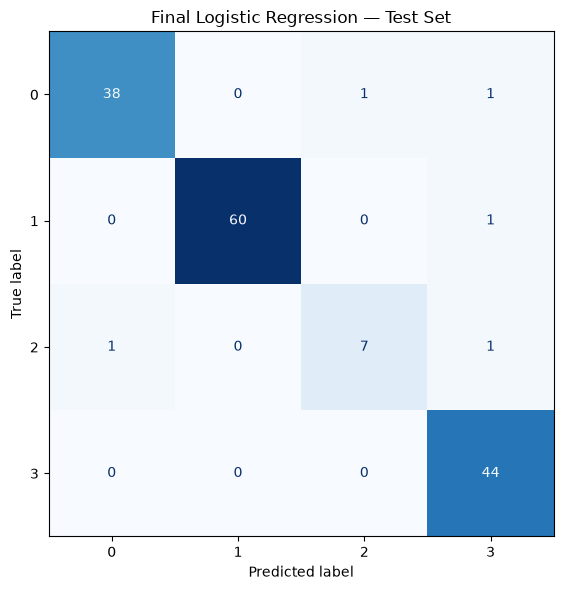

In [23]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=final_pipeline.classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Final Logistic Regression — Test Set")
fig.tight_layout()

fig.savefig(
    FIGURES_DIRECTORY / "final_test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [24]:
# Load the raw test features.
test_data = pd.read_csv(
    DATA_DIRECTORY / "test_labeled.csv",
    index_col="source_row",
)

X_test = test_data.loc[:, FEATURES].copy()

# Predictions before saving, used for the reload comparison.
test_predictions = final_pipeline.predict(X_test)

selected_sampler = search.best_params_["sampler"]

best_parameters = {
    "C": float(search.best_params_["classifier__C"]),
    "sampling": (
        "oversampling"
        if isinstance(selected_sampler, RandomOverSampler)
        else "no sampling"
    ),
}

final_bundle = {
    "pipeline": final_pipeline,
    "model_name": "Logistic Regression",
    "features": list(FEATURES),
    "risk_mapping": clustering_bundle["risk_mapping"],
    "selected_k": clustering_bundle["selected_k"],
    "best_parameters": best_parameters,
    "cv_f1": float(search.best_score_),
    "test_metrics": final_metrics.loc["Test"].to_dict(),
    "target": "Cluster",
    "status": "tuned_and_test_evaluated",
}

model_path = MODELS_DIRECTORY / "classification_final.joblib"
joblib.dump(final_bundle, model_path)

# Verify that saving and reloading preserves predictions.
loaded_bundle = joblib.load(model_path)
loaded_predictions = loaded_bundle["pipeline"].predict(X_test)

np.testing.assert_array_equal(
    test_predictions,
    loaded_predictions,
)

print("Final model saved:", model_path)
print("Reload verification passed.")
print("Selected parameters:", best_parameters)

Final model saved: /home/bsar/Desktop/diabetes-profile-ai/models/classification_final.joblib
Reload verification passed.
Selected parameters: {'C': 1.0, 'sampling': 'oversampling'}
